# BÀI THỰC HÀNH 5: CÂY QUYẾT ĐỊNH VÀ RỪNG NGẪU NHIÊN

In [ ]:

import os
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.inspection import permutation_importance
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
data_dir = "data" if os.path.exists("data") else "Lab05_data/data"
path_khach_vay = os.path.join(data_dir, "khach_vay.csv")
path_gia_nha = os.path.join(data_dir, "gia_nha.csv")
print("Nạp thư viện thành công!")
print(f"File khach_vay: {path_khach_vay} (tồn tại: {os.path.exists(path_khach_vay)})")
print(f"File gia_nha  : {path_gia_nha} (tồn tại: {os.path.exists(path_gia_nha)})")


Nạp thư viện thành công!
File khach_vay: data\khach_vay.csv (tồn tại: True)
File gia_nha  : data\gia_nha.csv (tồn tại: True)


---
## 1. TỰ TÍNH CHỈ SỐ GINI VÀ CHỌN CÂU HỎI TỐT NHẤT (f1_gini.py)

### 1.1. Công thức tính toán
Một câu hỏi tốt là câu hỏi tách dữ liệu thành hai nhánh, mỗi nhánh càng **thuần** càng tốt (gần như chỉ chứa mẫu của một lớp). Để đo mức độ lẫn lộn của một nút, thuật toán dùng **chỉ số Gini**:

$$G = 1 - p_1^2 - p_0^2$$

- Trong đó $p_1$ là tỷ lệ mẫu lớp 1 (trả đúng hạn), $p_0 = 1 - p_1$ là tỷ lệ mẫu lớp 0 (trễ hạn).
- Nút thuần khiết hoàn toàn: $G = 0$.
- Nút chia đôi lẫn lộn nhất ($p_1 = p_0 = 0.5$): $G = 0.5$.

Khi câu hỏi chia nút có $n$ mẫu thành nhánh trái ($n_T$ mẫu) và nhánh phải ($n_P$ mẫu), Gini trung bình có trọng số sau khi chia là:

$$G_{chia} = \frac{n_T}{n} G_T + \frac{n_P}{n} G_P$$

Mức giảm Gini:
$$\Delta G = G_{gốc} - G_{chia}$$
Câu hỏi tốt nhất là câu hỏi làm $G_{chia}$ nhỏ nhất, tức là làm Gini giảm nhiều nhất ($\Delta G$ cực đại).


Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
 nguong   Gini sau chia   Gini giam
    7.0          0.4000      0.0800
    8.5          0.4750      0.0050
   10.0          0.4190      0.0610
   12.0          0.3167      0.1633
   14.0          0.4000      0.0800
   16.5          0.4500      0.0300
   19.0          0.3429      0.1371
   22.5          0.4000      0.0800
   27.5          0.4444      0.0356

Cau hoi 'co viec on dinh ?'
 Gini sau chia 0.4190, Gini giam 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



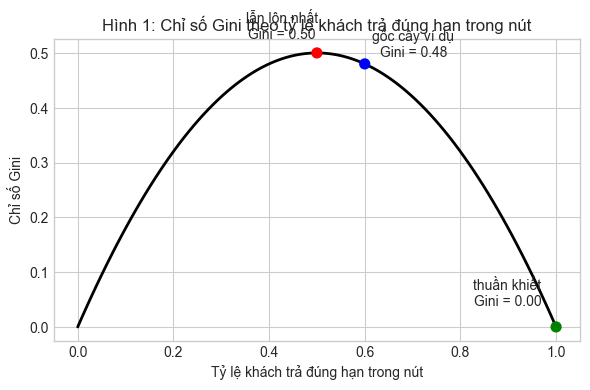

In [ ]:
nho = pd.DataFrame({
    "thu_nhap": [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han": [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y = nho["tra_dung_han"].to_numpy()

def gini(nhan):
    """Chỉ số Gini của một nút có hai lớp."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2

def gini_sau_chia(di_trai):
    """Gini trung bình có trọng số của hai nhánh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)

g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}\n")

thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print(" nguong   Gini sau chia   Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f" {nguong:6.1f}   {g:13.4f}   {g_goc - g:9.4f}")
print()

viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f" Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}\n")

cot = ["thu_nhap", "co_viec_on_dinh"]
cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nho[cot], y)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))

p1_range = np.linspace(0, 1, 100)
gini_curve = 1 - p1_range**2 - (1 - p1_range)**2
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(p1_range, gini_curve, 'k-', lw=2)
ax.scatter([0.5, 0.6, 1.0], [0.5, 0.48, 0.0], color=['red', 'blue', 'green'], s=50, zorder=5)
ax.annotate('lẫn lộn nhất\nGini = 0.50', (0.5, 0.5), textcoords="offset points", xytext=(-25, 10), ha='center')
ax.annotate('gốc cây ví dụ\nGini = 0.48', (0.6, 0.48), textcoords="offset points", xytext=(35, 5), ha='center')
ax.annotate('thuần khiết\nGini = 0.00', (1.0, 0.0), textcoords="offset points", xytext=(-35, 15), ha='center')
ax.set_xlabel('Tỷ lệ khách trả đúng hạn trong nút')
ax.set_ylabel('Chỉ số Gini')
ax.set_title('Hình 1: Chỉ số Gini theo tỷ lệ khách trả đúng hạn trong nút')
plt.tight_layout()
plt.show()


---
## 2. CÂY ĐẦU TIÊN TRÊN DỮ LIỆU KHÁCH VAY 


Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accu

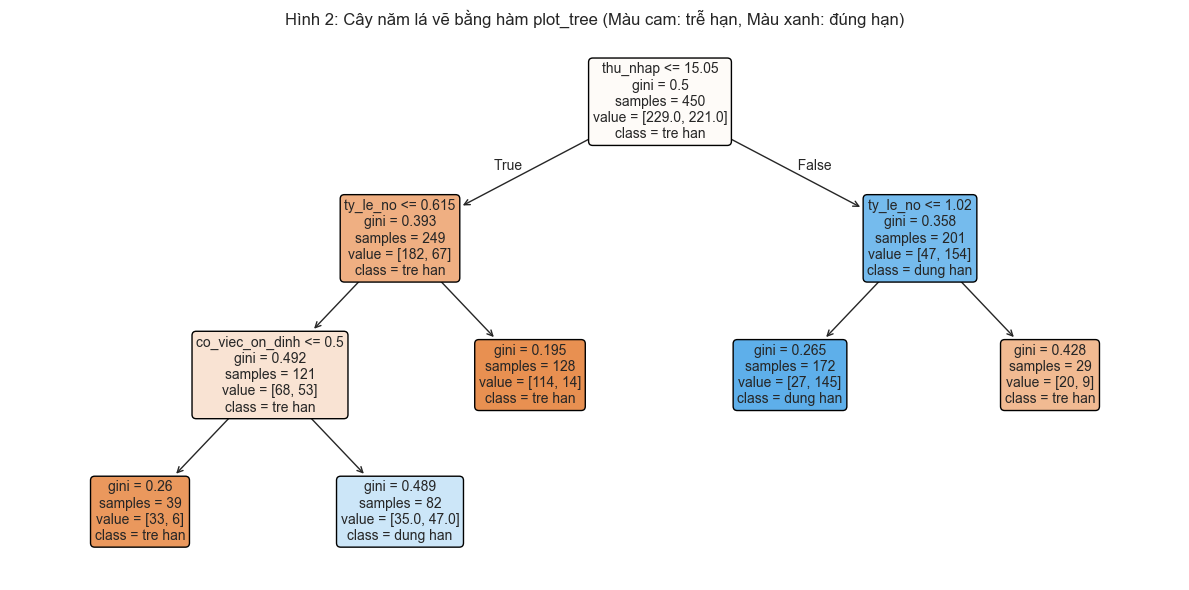

In [ ]:
df = pd.read_csv(path_khach_vay)
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))
print()

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Giới hạn cây chỉ có 5 lá
cay_5la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay_5la.fit(X_tr, y_tr)

print(f"Do sau {cay_5la.get_depth()}, so la {cay_5la.get_n_leaves()}")
print(export_text(cay_5la, feature_names=list(X.columns), show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay_5la.predict(X_tr))
a_kt = accuracy_score(y_te, cay_5la.predict(X_te))
print(f"Accuracy tap hoc      : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}")
print()

# Dự đoán cho 2 khách hàng mới
moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})
du_doan = cay_5la.predict(moi)
xac_suat = cay_5la.predict_proba(moi)[:, 1]
for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

# Vẽ cây năm lá trực quan (Hình 2 trong PDF)
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(cay_5la, feature_names=list(X.columns), class_names=["tre han", "dung han"],
          filled=True, rounded=True, fontsize=10, ax=ax)
plt.title("Hình 2: Cây năm lá vẽ bằng hàm plot_tree (Màu cam: trễ hạn, Màu xanh: đúng hạn)")
plt.tight_layout()
plt.show()


---
## 3. CÂY HỌC VẸT VÀ CÁCH CHỌN ĐỘ SÂU BẰNG KIỂM ĐỊNH CHÉO 


Cay moc tu do
 do sau 13, so la 92
 tap hoc 1.0000, tap kiem tra 0.7667

Do sau   tap hoc   kiem dinh cheo
   1      0.7467       0.7244
   2      0.7711       0.7378
   3      0.8000       0.7511
   4      0.8644       0.8089
   5      0.8978       0.8333
   6      0.9133       0.8156
   7      0.9400       0.8067
   8      0.9600       0.7733
   9      0.9800       0.7800
  10      0.9911       0.7822
  11      0.9933       0.7756
  12      0.9978       0.7778
  13      1.0000       0.7733
  14      1.0000       0.7733
  15      1.0000       0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


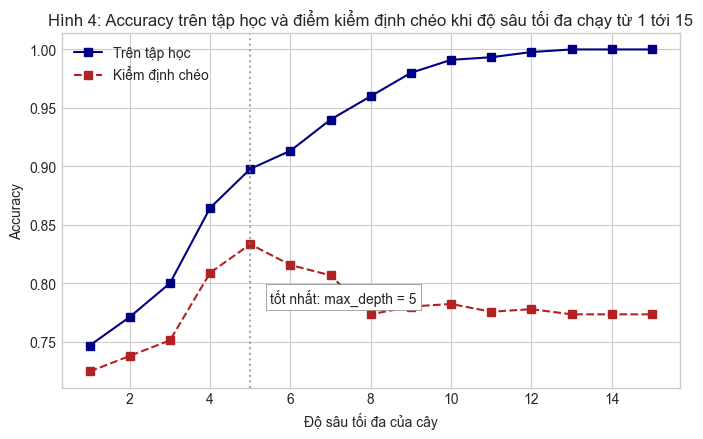

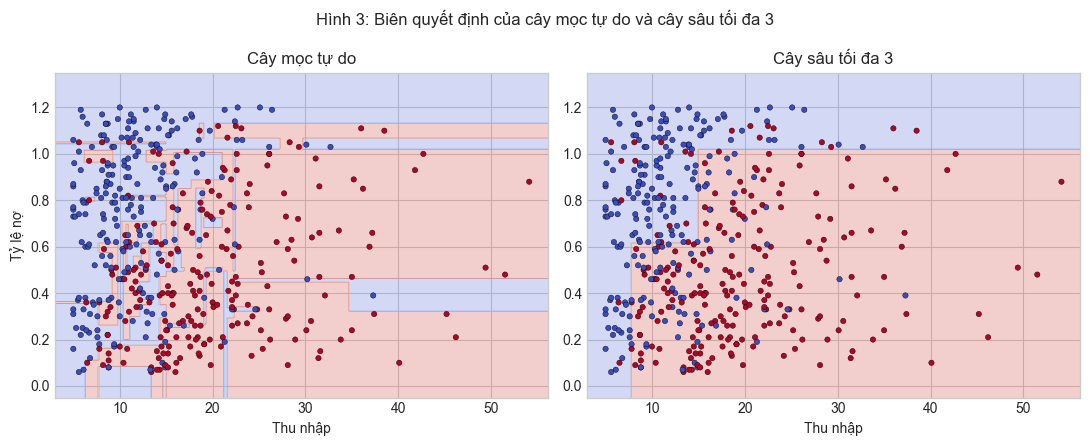

In [ ]:
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f" do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f" tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}\n")

# 2. Chọn độ sâu chỉ dựa trên tập học bằng kiểm định chéo
print("Do sau   tap hoc   kiem dinh cheo")
diem = {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f"  {d:2d}      {hoc:.4f}       {diem[d]:.4f}")

d_tot = max(diem, key=diem.get)
print()

# Chọn xong mới mở tập kiểm tra
tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0)
tot.fit(X_tr, y_tr)
print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

# Vẽ đồ thị Hình 4: Accuracy tập học vs Điểm kiểm định chéo
do_sau_list = list(range(1, 16))
train_scores = [accuracy_score(y_tr, DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_tr, y_tr).predict(X_tr)) for d in do_sau_list]
cv_scores = [diem[d] for d in do_sau_list]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(do_sau_list, train_scores, 's-', color='navy', label='Trên tập học')
ax.plot(do_sau_list, cv_scores, 's--', color='firebrick', label='Kiểm định chéo')
ax.axvline(d_tot, color='gray', linestyle=':', alpha=0.7)
ax.annotate(f'tốt nhất: max_depth = {d_tot}', xy=(d_tot, diem[d_tot]), xytext=(d_tot + 0.5, diem[d_tot] - 0.05),
            bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="gray", lw=0.5))
ax.set_xlabel('Độ sâu tối đa của cây')
ax.set_ylabel('Accuracy')
ax.set_title('Hình 4: Accuracy trên tập học và điểm kiểm định chéo khi độ sâu tối đa chạy từ 1 tới 15')
ax.legend()
plt.tight_layout()
plt.show()

X2_tr = X_tr[["thu_nhap", "ty_le_no"]].to_numpy()
y2_tr = y_tr.to_numpy()

cay_td2 = DecisionTreeClassifier(random_state=0).fit(X2_tr, y2_tr)
cay_s3 = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X2_tr, y2_tr)

x_min, x_max = X2_tr[:, 0].min() - 2, X2_tr[:, 0].max() + 2
y_min, y_max = -0.05, 1.35
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, title in [(ax1, cay_td2, 'Cây mọc tự do'), (ax2, cay_s3, 'Cây sâu tối đa 3')]:
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap=plt.cm.coolwarm)
    scatter = ax.scatter(X2_tr[:, 0], X2_tr[:, 1], c=y2_tr, cmap=plt.cm.coolwarm, s=15, edgecolors='k', linewidth=0.3)
    ax.set_xlabel('Thu nhập')
    ax.set_ylabel('Tỷ lệ nợ' if ax == ax1 else '')
    ax.set_title(title)
plt.suptitle('Hình 3: Biên quyết định của cây mọc tự do và cây sâu tối đa 3')
plt.tight_layout()
plt.show()


---
## 4. KIỂM CHỨNG CÂY QUYẾT ĐỊNH KHÔNG CẦN CHUẨN HOÁ DỮ LIỆU 



In [5]:
# Kiểm chứng 3 cây sâu 5 trên cùng tập học với các thang đo khác nhau

def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)

# Cây 1: Dữ liệu gốc
goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

# Cây 2: Chuẩn hoá Z-score bằng StandardScaler
sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

# Cây 3: Đổi thu nhập từ triệu đồng sang nghìn đồng (nhân 1000)
X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

print("Accuracy tren tap kiem tra")
print(f" du lieu goc          : {accuracy_score(y_te, du_goc):.4f}")
print(f" da chuan hoa         : {accuracy_score(y_te, du_chuan):.4f}")
print(f" thu nhap nghin dong  : {accuracy_score(y_te, du_nghin):.4f}")
print()
print("So khach bi doan khac cay goc")
print(f" da chuan hoa         : {(du_chuan != du_goc).sum()}")
print(f" thu nhap nghin dong  : {(du_nghin != du_goc).sum()}")
print()
print("Nguong cua cau hoi goc")
print(f" du lieu goc          : {goc.tree_.threshold[0]:.2f}")
print(f" thu nhap nghin dong  : {nghin.tree_.threshold[0]:.2f}")


Accuracy tren tap kiem tra
 du lieu goc          : 0.8533
 da chuan hoa         : 0.8533
 thu nhap nghin dong  : 0.8533

So khach bi doan khac cay goc
 da chuan hoa         : 0
 thu nhap nghin dong  : 0

Nguong cua cau hoi goc
 du lieu goc          : 15.05
 thu nhap nghin dong  : 15050.00


---
## 5. RỪNG NGẪU NHIÊN (RANDOM FOREST) 



Boc 450 lan, co 286 khach khac nhau (64%)

Rung 200 cay
 tap hoc      : 1.0000
 tap kiem tra : 0.9000

So cay   accuracy tap kiem tra
     1   0.7933
    10   0.8467
    50   0.8733
   200   0.9000
   400   0.9000

Mo hinh          tap hoc   tap kiem tra
 Cay moc tu do   1.0000    0.7667
 Cay sau 5       0.8978    0.8533
 Rung 200 cay    1.0000    0.9000


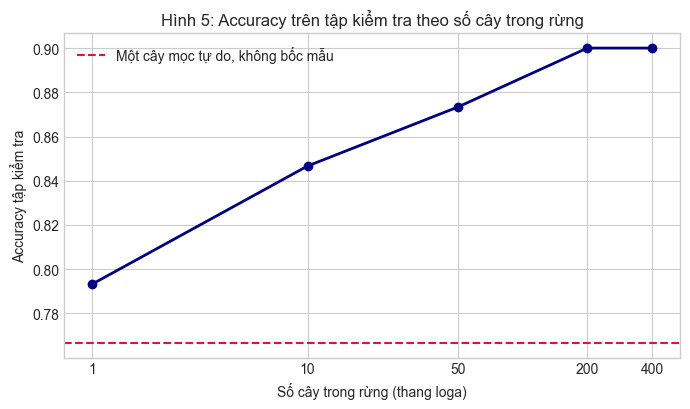

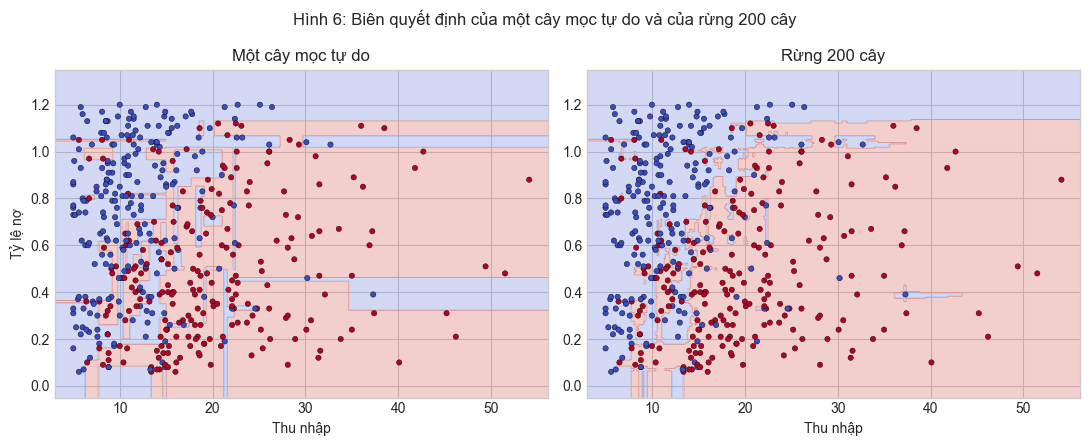

In [6]:
# Trồng rừng ngẫu nhiên và so sánh với cây đơn lẻ

# 1. Minh họa bốc mẫu có hoàn lại
rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})\n")

# 2. Huấn luyện rừng 200 cây
rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f" tap hoc      : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f" tap kiem tra : {accuracy_score(y_te, rung.predict(X_te)):.4f}\n")

# 3. Khảo sát số lượng cây trong rừng
print("So cay   accuracy tap kiem tra")
so_cay_list = [1, 10, 50, 200, 400]
acc_rung_list = []
for m in so_cay_list:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    a = accuracy_score(y_te, r.predict(X_te))
    acc_rung_list.append(a)
    print(f"  {m:4d}   {a:.4f}")
print()

# 4. Bảng tổng kết 3 mô hình (Bảng 5 trong PDF)
ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5"    : DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay" : rung,
}
print("Mo hinh          tap hoc   tap kiem tra")
for ten, mh in ba_mo_hinh.items():
    mh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mh.predict(X_tr))
    b = accuracy_score(y_te, mh.predict(X_te))
    print(f" {ten:14s}  {a:.4f}    {b:.4f}")

# Vẽ đồ thị Hình 5: Accuracy trên tập kiểm tra theo số cây trong rừng
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(so_cay_list, acc_rung_list, 'o-', color='navy', lw=2)
ax.axhline(0.7667, color='crimson', linestyle='--', label='Một cây mọc tự do, không bốc mẫu')
ax.set_xscale('log')
ax.set_xticks(so_cay_list)
ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax.set_xlabel('Số cây trong rừng (thang loga)')
ax.set_ylabel('Accuracy tập kiểm tra')
ax.set_title('Hình 5: Accuracy trên tập kiểm tra theo số cây trong rừng')
ax.legend()
plt.tight_layout()
plt.show()

# Vẽ biên quyết định Cây tự do vs Rừng 200 cây (Hình 6 trong PDF)
rung2 = RandomForestClassifier(n_estimators=200, random_state=0).fit(X2_tr, y2_tr)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, title in [(ax1, cay_td2, 'Một cây mọc tự do'), (ax2, rung2, 'Rừng 200 cây')]:
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap=plt.cm.coolwarm)
    ax.scatter(X2_tr[:, 0], X2_tr[:, 1], c=y2_tr, cmap=plt.cm.coolwarm, s=15, edgecolors='k', linewidth=0.3)
    ax.set_xlabel('Thu nhập')
    ax.set_ylabel('Tỷ lệ nợ' if ax == ax1 else '')
    ax.set_title(title)
plt.suptitle('Hình 6: Biên quyết định của một cây mọc tự do và của rừng 200 cây')
plt.tight_layout()
plt.show()


---
## 6. ĐỘ QUAN TRỌNG CỦA ĐẶC TRƯNG



Do quan trong, bon cot that
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0

Do quan trong, them mot cot ngau nhien
thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076


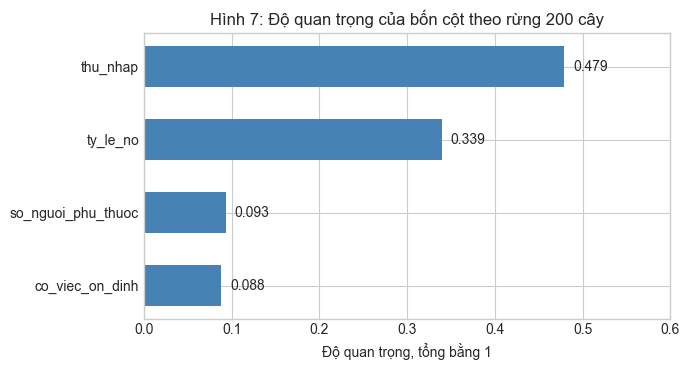

In [7]:
# Đọc độ quan trọng của đặc trưng và bộc lộ giới hạn của MDI

# 1. Rừng trên 4 đặc trưng thật
qt = pd.Series(rung.feature_importances_, index=X.columns)
print("Do quan trong, bon cot that")
print(qt.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(qt.sum(), 3))
print()

# 2. Thêm một cột ngẫu nhiên hoàn toàn độc lập vào tập học
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)

qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong, them mot cot ngau nhien")
print(qt_nn.sort_values(ascending=False).round(3).to_string())

# Vẽ biểu đồ thanh ngang Hình 7
fig, ax = plt.subplots(figsize=(7, 3.8))
qt_sorted = qt.sort_values(ascending=True)
bars = ax.barh(qt_sorted.index, qt_sorted.values, color='steelblue', height=0.55)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.01, bar.get_y() + bar.get_height()/2, f'{w:.3f}', va='center', fontsize=10)
ax.set_xlim(0, 0.6)
ax.set_xlabel('Độ quan trọng, tổng bằng 1')
ax.set_title('Hình 7: Độ quan trọng của bốn cột theo rừng 200 cây')
plt.tight_layout()
plt.show()


---
## 7. CÂY QUYẾT ĐỊNH CHO BÀI TOÁN HỒI QUY 


Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE tren tap kiem tra (ty dong)
 Cay sau 3    : 0.5039
 Duong thang  : 0.2578

Du doan cho bon can moi (ty dong)
 dien tich   cay   duong thang
     60 m2     4.92     5.12
    100 m2     8.32     8.24
    150 m2     9.40    12.13
    250 m2     9.40    19.91


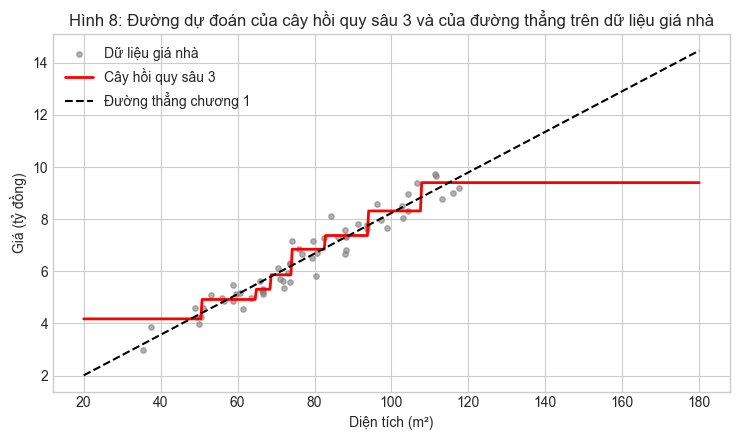

In [8]:
# Cây hồi quy và Hồi quy tuyến tính trên dữ liệu giá nhà

df_nha = pd.read_csv(path_gia_nha)
X_nha = df_nha[["dien_tich"]]
y_nha = df_nha["gia"]

# Phân chia 80% train, 20% test giống Bài 1
X_tr_nha, X_te_nha, y_tr_nha, y_te_nha = train_test_split(
    X_nha, y_nha, test_size=0.2, random_state=42
)

cay_reg = DecisionTreeRegressor(max_depth=3, random_state=0)
cay_reg.fit(X_tr_nha, y_tr_nha)
duong_reg = LinearRegression().fit(X_tr_nha, y_tr_nha)

print(f"Cay hoi quy sau 3 co {cay_reg.get_n_leaves()} la")
print(export_text(cay_reg, feature_names=["dien_tich"], decimals=1))

mae_cay = mean_absolute_error(y_te_nha, cay_reg.predict(X_te_nha))
mae_duong = mean_absolute_error(y_te_nha, duong_reg.predict(X_te_nha))
print("MAE tren tap kiem tra (ty dong)")
print(f" Cay sau 3    : {mae_cay:.4f}")
print(f" Duong thang  : {mae_duong:.4f}\n")

# Dự đoán cho 4 căn nhà mới
can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print(" dien tich   cay   duong thang")
for dt, a, b in zip(can_moi["dien_tich"], cay_reg.predict(can_moi), duong_reg.predict(can_moi)):
    print(f" {dt:6.0f} m2   {a:6.2f}   {b:6.2f}")

# Vẽ đồ thị đường hồi quy bậc thang (Hình 8 trong PDF)
x_plot = pd.DataFrame({"dien_tich": np.linspace(20, 180, 500)})
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(df_nha["dien_tich"], df_nha["gia"], color='gray', alpha=0.6, s=15, label='Dữ liệu giá nhà')
ax.plot(x_plot["dien_tich"], cay_reg.predict(x_plot), 'r-', lw=2, label='Cây hồi quy sâu 3')
ax.plot(x_plot["dien_tich"], duong_reg.predict(x_plot), 'k--', lw=1.5, label='Đường thẳng chương 1')
ax.set_xlabel('Diện tích (m²)')
ax.set_ylabel('Giá (tỷ đồng)')
ax.set_title('Hình 8: Đường dự đoán của cây hồi quy sâu 3 và của đường thẳng trên dữ liệu giá nhà')
ax.legend()
plt.tight_layout()
plt.show()


---
## 8. BÀI TẬP 1: TỰ VẼ CÂY QUYẾT ĐỊNH 



Đã lưu hình ảnh cây 5 lá thành công vào tệp 'cay_nam_la.png'!
Cấu trúc cây sâu 2 dạng chữ:
|--- thu_nhap <= 15.05
|   |--- ty_le_no <= 0.62
|   |   |--- weights: [68.00, 53.00] class: 0
|   |--- ty_le_no >  0.62
|   |   |--- weights: [114.00, 14.00] class: 0
|--- thu_nhap >  15.05
|   |--- ty_le_no <= 1.02
|   |   |--- weights: [27.00, 145.00] class: 1
|   |--- ty_le_no >  1.02
|   |   |--- weights: [20.00, 9.00] class: 0



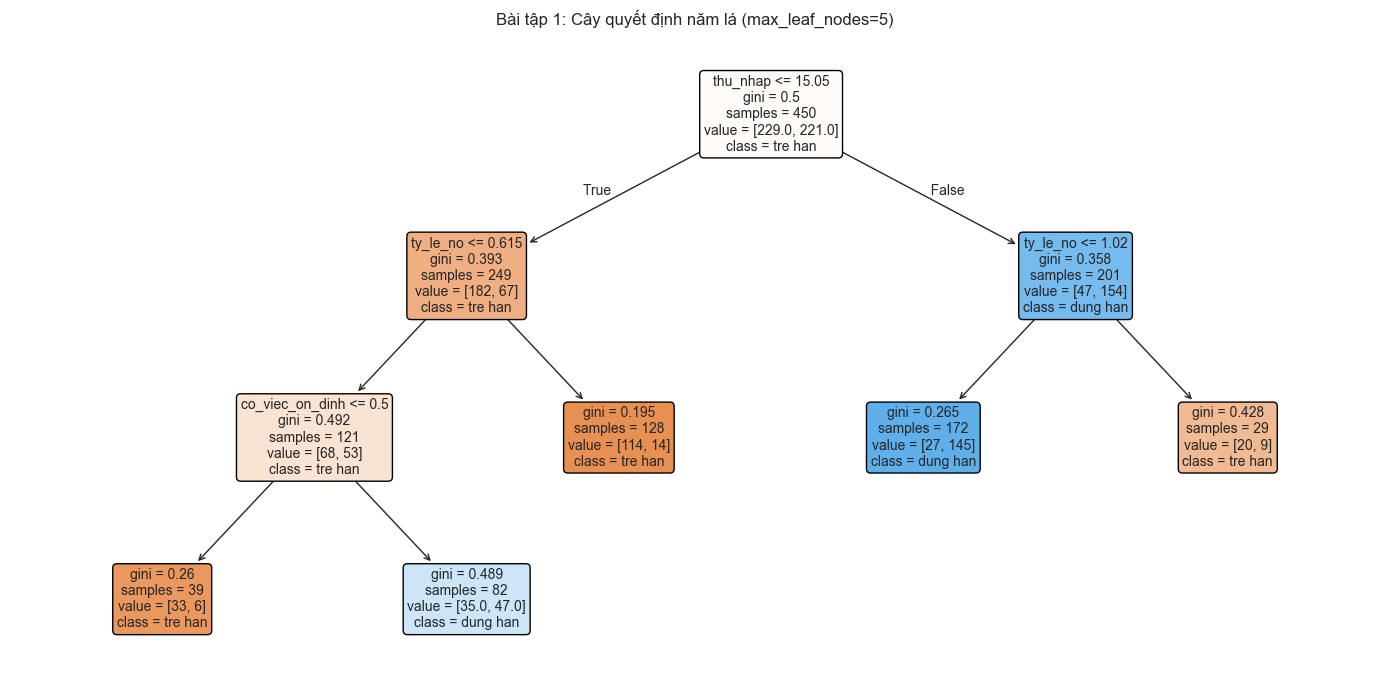

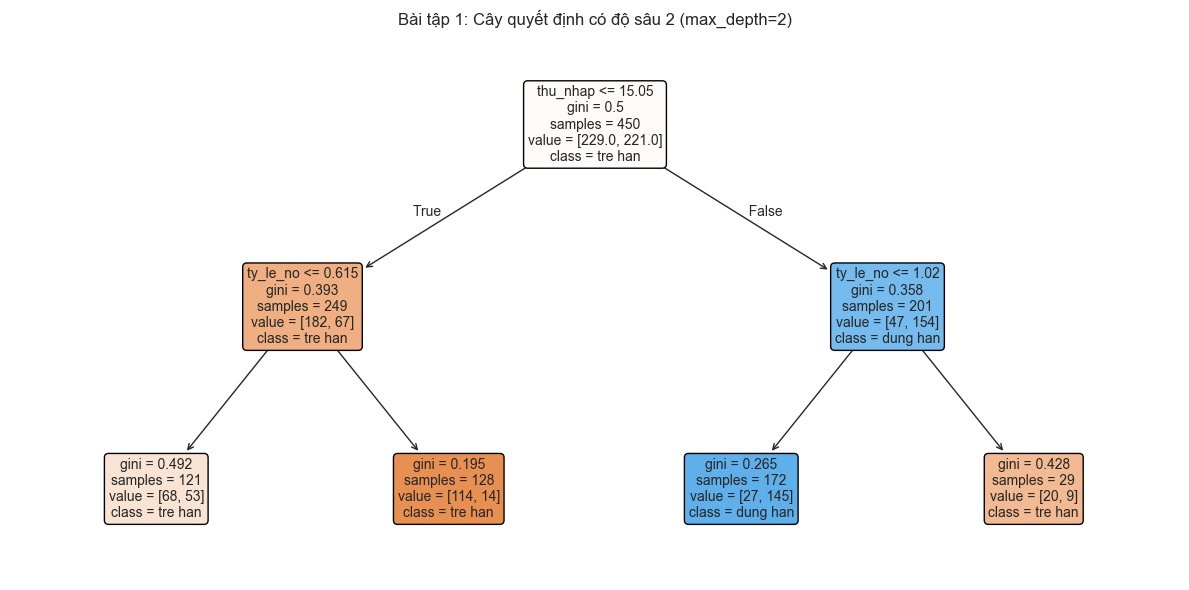

In [9]:
# BÀI TẬP 1: Vẽ cây 5 lá, lưu file cay_nam_la.png và phân tích cây max_depth=2

# 1. Vẽ cây 5 lá và lưu thành tệp cay_nam_la.png
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(cay_5la, feature_names=list(X.columns), class_names=["tre han", "dung han"],
          filled=True, rounded=True, fontsize=10, ax=ax)
plt.title("Bài tập 1: Cây quyết định năm lá (max_leaf_nodes=5)")
plt.tight_layout()
plt.savefig("cay_nam_la.png", dpi=150, bbox_inches='tight')
print("Đã lưu hình ảnh cây 5 lá thành công vào tệp 'cay_nam_la.png'!")
plt.show()

# 2. Huấn luyện và vẽ cây sâu 2 (max_depth=2)
cay_depth2 = DecisionTreeClassifier(max_depth=2, random_state=0)
cay_depth2.fit(X_tr, y_tr)

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(cay_depth2, feature_names=list(X.columns), class_names=["tre han", "dung han"],
          filled=True, rounded=True, fontsize=10, ax=ax)
plt.title("Bài tập 1: Cây quyết định có độ sâu 2 (max_depth=2)")
plt.tight_layout()
plt.show()

print("Cấu trúc cây sâu 2 dạng chữ:")
print(export_text(cay_depth2, feature_names=list(X.columns), show_weights=True, decimals=2))


---
## 9. BÀI TẬP 2: TỰ TÌM CÂU HỎI GỐC TRÊN DỮ LIỆU THẬT 



In [10]:
# BÀI TẬP 2: Tự viết hàm tìm câu hỏi tối ưu hóa mức giảm Gini trên tập học

def tim_cau_hoi(X, y):
    """
    Thử nghiệm mọi cột và mọi ngưỡng khả dĩ để tìm phép chia làm Gini giảm nhiều nhất.
    Trả về: (cột tốt nhất, ngưỡng tốt nhất, mức Gini giảm lớn nhất)
    """
    y_arr = y.to_numpy() if isinstance(y, (pd.Series, pd.DataFrame)) else np.array(y)
    n = len(y_arr)
    g_goc = gini(y_arr)
    
    best_giam = -1.0
    best_col = None
    best_threshold = None
    
    for col in X.columns:
        vals = X[col].to_numpy()
        unique_vals = np.sort(np.unique(vals))
        
        # Ngưỡng là trung điểm giữa 2 giá trị liên tiếp
        thresholds = (unique_vals[:-1] + unique_vals[1:]) / 2.0
        
        for th in thresholds:
            di_trai = (vals <= th)
            di_phai = ~di_trai
            
            y_trai = y_arr[di_trai]
            y_phai = y_arr[di_phai]
            
            # Gini sau chia có trọng số
            g_chia = (len(y_trai) / n) * gini(y_trai) + (len(y_phai) / n) * gini(y_phai)
            g_giam = g_goc - g_chia
            
            if g_giam > best_giam:
                best_giam = g_giam
                best_col = col
                best_threshold = th
                
    return best_col, best_threshold, best_giam

# Thực thi trên 450 khách hàng của tập học
cot_opt, nguong_opt, giam_opt = tim_cau_hoi(X_tr, y_tr)
print("=== KẾT QUẢ TỰ TÍNH TOÁN (BÀI TẬP 2) ===")
print(f"Cột tốt nhất  : {cot_opt}")
print(f"Ngưỡng tối ưu : {nguong_opt:.4f}")
print(f"Mức Gini giảm : {giam_opt:.4f}")
print()

# Kiểm chứng đối chiếu với Scikit-Learn
cay_check = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_tr, y_tr)
sklearn_col = X_tr.columns[cay_check.tree_.feature[0]]
sklearn_th = cay_check.tree_.threshold[0]
print("=== ĐỐI CHIẾU VỚI SCIKIT-LEARN ===")
print(f"Cột của Scikit-Learn : {sklearn_col}")
print(f"Ngưỡng Scikit-Learn  : {sklearn_th:.4f}")
assert cot_opt == sklearn_col and abs(nguong_opt - sklearn_th) < 1e-4, "Kết quả không khớp!"
print("=> KẾT QUẢ HOÀN TOÀN TRÙNG KHỚP VỚI CÂU HỎI GỐC CỦA TÀI LIỆU (15.05)!")


=== KẾT QUẢ TỰ TÍNH TOÁN (BÀI TẬP 2) ===
Cột tốt nhất  : thu_nhap
Ngưỡng tối ưu : 15.0500
Mức Gini giảm : 0.1221

=== ĐỐI CHIẾU VỚI SCIKIT-LEARN ===
Cột của Scikit-Learn : thu_nhap
Ngưỡng Scikit-Learn  : 15.0500
=> KẾT QUẢ HOÀN TOÀN TRÙNG KHỚP VỚI CÂU HỎI GỐC CỦA TÀI LIỆU (15.05)!


---
## 10. BÀI TẬP 3: GINI HAY ENTROPY



Do sau   tap hoc   kiem dinh cheo (Entropy)
   1      0.7467       0.7244
   2      0.7711       0.7133
   3      0.7733       0.7489
   4      0.8511       0.8111
   5      0.8956       0.8222
   6      0.9111       0.8222
   7      0.9378       0.8089
   8      0.9533       0.7933
   9      0.9778       0.7844
  10      0.9867       0.7978
  11      0.9933       0.7911
  12      0.9978       0.7822
  13      1.0000       0.7822
  14      1.0000       0.7822
  15      1.0000       0.7867

Độ sâu tốt nhất (Entropy): 5 (CV score = 0.8222)
Accuracy tập kiểm tra (Entropy): 0.8467
Đối chiếu Gini ở mục 4: Độ sâu 5, CV score = 0.8333, Test Accuracy = 0.8533


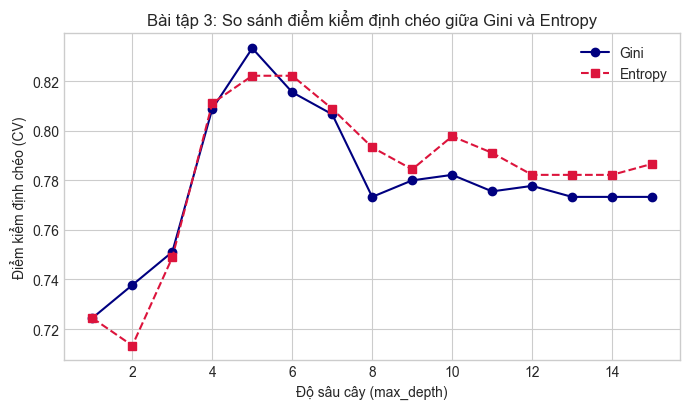

In [11]:
# BÀI TẬP 3: Khảo sát độ sâu với tiêu chí Entropy (Information Gain)

diem_entropy = {}
print("Do sau   tap hoc   kiem dinh cheo (Entropy)")
for d in range(1, 16):
    mh = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0)
    diem_entropy[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f"  {d:2d}      {hoc:.4f}       {diem_entropy[d]:.4f}")

d_tot_entropy = max(diem_entropy, key=diem_entropy.get)
tot_entropy = DecisionTreeClassifier(criterion="entropy", max_depth=d_tot_entropy, random_state=0)
tot_entropy.fit(X_tr, y_tr)
acc_entropy = accuracy_score(y_te, tot_entropy.predict(X_te))

print()
print(f"Độ sâu tốt nhất (Entropy): {d_tot_entropy} (CV score = {diem_entropy[d_tot_entropy]:.4f})")
print(f"Accuracy tập kiểm tra (Entropy): {acc_entropy:.4f}")
print(f"Đối chiếu Gini ở mục 4: Độ sâu 5, CV score = 0.8333, Test Accuracy = 0.8533")

# Vẽ đồ thị so sánh CV score giữa Gini và Entropy
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(range(1, 16), [diem[d] for d in range(1, 16)], 'o-', color='navy', label='Gini')
ax.plot(range(1, 16), [diem_entropy[d] for d in range(1, 16)], 's--', color='crimson', label='Entropy')
ax.set_xlabel('Độ sâu cây (max_depth)')
ax.set_ylabel('Điểm kiểm định chéo (CV)')
ax.set_title('Bài tập 3: So sánh điểm kiểm định chéo giữa Gini và Entropy')
ax.legend()
plt.tight_layout()
plt.show()


---
## 11. BÀI TẬP 4: CẮT TỈA BẰNG SỐ KHÁCH TỐI THIỂU Ở LÁ 


min_samples_leaf   tap hoc   kiem dinh cheo
       1            1.0000       0.7733
       2            0.9467       0.7822
       5            0.8956       0.8067
      10            0.8600       0.8089
      20            0.8422       0.8089
      40            0.7822       0.7133

Giá trị min_samples_leaf tốt nhất: 10 (CV score = 0.8089)
Accuracy trên tập kiểm tra: 0.8467
Đối chiếu cây sâu 5 (max_depth=5): CV = 0.8333, Test Accuracy = 0.8533


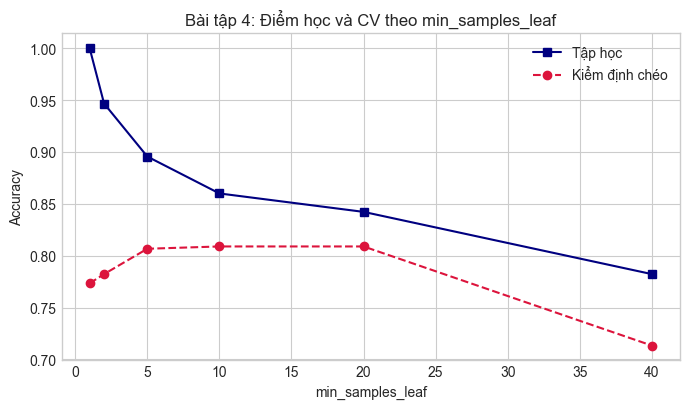

In [12]:
# BÀI TẬP 4: Khảo sát cắt tỉa cây bằng tham số min_samples_leaf

leaf_list = [1, 2, 5, 10, 20, 40]
diem_leaf = {}
train_leaf = {}

print("min_samples_leaf   tap hoc   kiem dinh cheo")
for msl in leaf_list:
    mh = DecisionTreeClassifier(min_samples_leaf=msl, random_state=0)
    diem_leaf[msl] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    train_leaf[msl] = hoc
    print(f"      {msl:2d}            {hoc:.4f}       {diem_leaf[msl]:.4f}")

msl_tot = max(diem_leaf, key=diem_leaf.get)
tot_leaf = DecisionTreeClassifier(min_samples_leaf=msl_tot, random_state=0).fit(X_tr, y_tr)
acc_leaf = accuracy_score(y_te, tot_leaf.predict(X_te))

print()
print(f"Giá trị min_samples_leaf tốt nhất: {msl_tot} (CV score = {diem_leaf[msl_tot]:.4f})")
print(f"Accuracy trên tập kiểm tra: {acc_leaf:.4f}")
print(f"Đối chiếu cây sâu 5 (max_depth=5): CV = 0.8333, Test Accuracy = 0.8533")

# Vẽ đồ thị so sánh
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(leaf_list, [train_leaf[m] for m in leaf_list], 's-', color='navy', label='Tập học')
ax.plot(leaf_list, [diem_leaf[m] for m in leaf_list], 'o--', color='crimson', label='Kiểm định chéo')
ax.set_xlabel('min_samples_leaf')
ax.set_ylabel('Accuracy')
ax.set_title('Bài tập 4: Điểm học và CV theo min_samples_leaf')
ax.legend()
plt.tight_layout()
plt.show()


---
## 12. BÀI TẬP 5: ĐỘ QUAN TRỌNG BẰNG CÁCH XÁO TRỘN 



BẢNG SO SÁNH ĐỘ QUAN TRỌNG ĐẶC TRƯNG:
                    MDI (feature_importances_)  Hạng MDI  Permutation Importance  Hạng Permutation
thu_nhap                              0.426871         1                0.307333                 1
ty_le_no                              0.269562         2                0.199333                 2
co_viec_on_dinh                       0.077281         4                0.111667                 3
so_nguoi_phu_thuoc                    0.076410         5                0.049667                 4
so_ngau_nhien                         0.149875         3                0.001667                 5


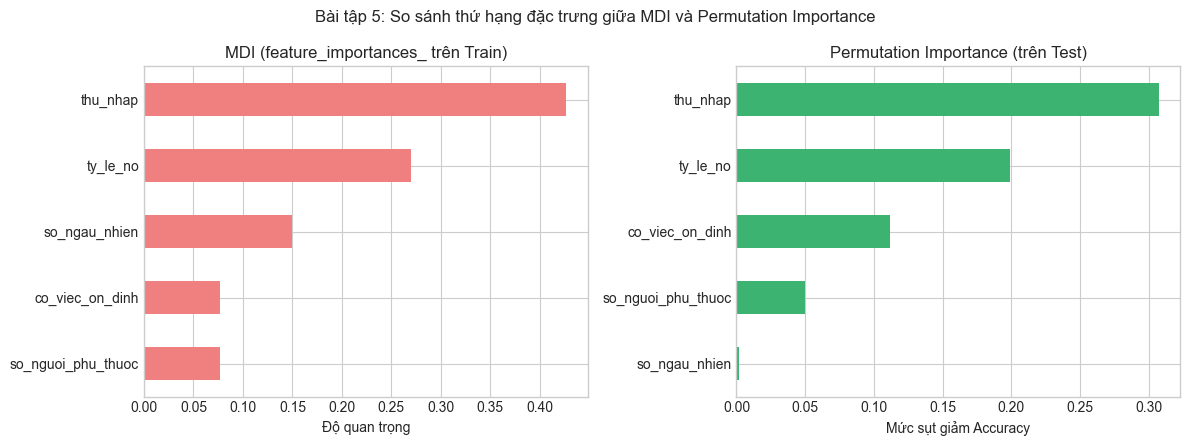

In [13]:
# BÀI TẬP 5: Đo độ quan trọng bằng Permutation Importance trên tập kiểm tra

# 1. Thêm cột ngẫu nhiên vào cả tập học và tập kiểm tra
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))

X_te_nn = X_te.copy()
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te))

# Huấn luyện Rừng 200 cây trên tập có cột ngẫu nhiên
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)

# 2. Tính Permutation Importance trên tập kiểm tra
res_perm = permutation_importance(rung_nn, X_te_nn, y_te, n_repeats=20, random_state=0)
perm_mean = pd.Series(res_perm.importances_mean, index=X_te_nn.columns)
mdi_score = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)

# 3. Tạo bảng so sánh đối chiếu giữa 2 phương pháp
df_compare = pd.DataFrame({
    "MDI (feature_importances_)": mdi_score,
    "Hạng MDI": mdi_score.rank(ascending=False).astype(int),
    "Permutation Importance": perm_mean,
    "Hạng Permutation": perm_mean.rank(ascending=False).astype(int)
}).sort_values(by="Permutation Importance", ascending=False)

print("BẢNG SO SÁNH ĐỘ QUAN TRỌNG ĐẶC TRƯNG:")
print(df_compare.to_string())

# Vẽ đồ thị so sánh đối đầu giữa MDI và Permutation Importance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
mdi_score.sort_values().plot(kind='barh', ax=ax1, color='lightcoral')
ax1.set_title("MDI (feature_importances_ trên Train)")
ax1.set_xlabel("Độ quan trọng")

perm_mean.sort_values().plot(kind='barh', ax=ax2, color='mediumseagreen')
ax2.set_title("Permutation Importance (trên Test)")
ax2.set_xlabel("Mức sụt giảm Accuracy")

plt.suptitle("Bài tập 5: So sánh thứ hạng đặc trưng giữa MDI và Permutation Importance")
plt.tight_layout()
plt.show()


---
## 13. BÀI TẬP 6: RỪNG CHO BÀI TOÁN HỒI QUY 



MAE TRÊN TẬP KIỂM TRA (TỶ ĐỒNG):
  Đường thẳng (Hồi quy tuyến tính) : 0.2578
  Rừng 200 cây (Random Forest)    : 0.4559
  Cây sâu 3 (Decision Tree)        : 0.5039

DỰ ĐOÁN GIÁ CĂN 250 m²:
  Đường thẳng   : 19.91 tỷ đồng
  Cây sâu 3     : 9.40 tỷ đồng
  Rừng 200 cây  : 9.20 tỷ đồng
  (Giá cao nhất trong tập học: 9.74 tỷ đồng)


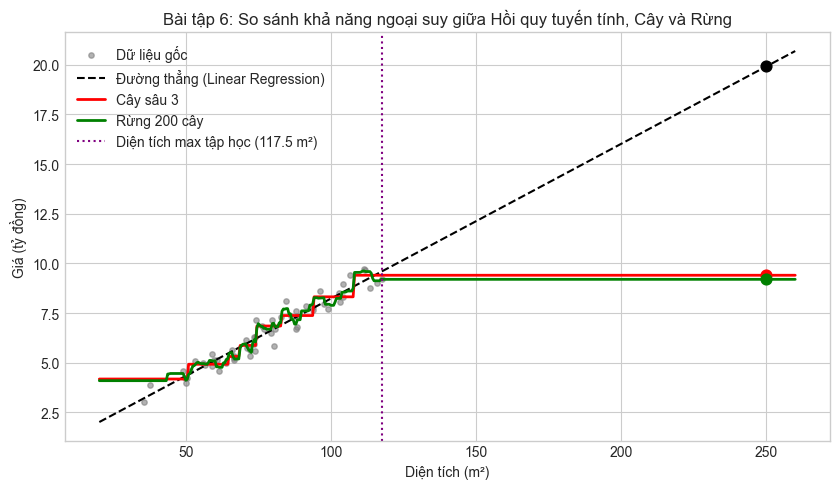

In [14]:
# BÀI TẬP 6: RandomForestRegressor trên dữ liệu giá nhà và phân tích khả năng ngoại suy

# 1. Huấn luyện Rừng hồi quy 200 cây
rung_reg = RandomForestRegressor(n_estimators=200, random_state=0)
rung_reg.fit(X_tr_nha, y_tr_nha)

# 2. So sánh MAE trên tập kiểm tra
mae_rung = mean_absolute_error(y_te_nha, rung_reg.predict(X_te_nha))

print("MAE TRÊN TẬP KIỂM TRA (TỶ ĐỒNG):")
print(f"  Đường thẳng (Hồi quy tuyến tính) : {mae_duong:.4f}")
print(f"  Rừng 200 cây (Random Forest)    : {mae_rung:.4f}")
print(f"  Cây sâu 3 (Decision Tree)        : {mae_cay:.4f}")
print()

# 3. Dự đoán cho căn 250 m2
can_250 = pd.DataFrame({"dien_tich": [250.0]})
gia_duong_250 = duong_reg.predict(can_250)[0]
gia_cay_250 = cay_reg.predict(can_250)[0]
gia_rung_250 = rung_reg.predict(can_250)[0]

print("DỰ ĐOÁN GIÁ CĂN 250 m²:")
print(f"  Đường thẳng   : {gia_duong_250:.2f} tỷ đồng")
print(f"  Cây sâu 3     : {gia_cay_250:.2f} tỷ đồng")
print(f"  Rừng 200 cây  : {gia_rung_250:.2f} tỷ đồng")
print(f"  (Giá cao nhất trong tập học: {y_tr_nha.max():.2f} tỷ đồng)")

# 4. Vẽ đồ thị so sánh đường dự đoán trên dải rộng [20, 260] m2
x_ext = pd.DataFrame({"dien_tich": np.linspace(20, 260, 500)})
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(df_nha["dien_tich"], df_nha["gia"], color='gray', alpha=0.6, s=15, label='Dữ liệu gốc')
ax.plot(x_ext["dien_tich"], duong_reg.predict(x_ext), 'k--', lw=1.5, label='Đường thẳng (Linear Regression)')
ax.plot(x_ext["dien_tich"], cay_reg.predict(x_ext), 'r-', lw=2, label='Cây sâu 3')
ax.plot(x_ext["dien_tich"], rung_reg.predict(x_ext), 'g-', lw=2, label='Rừng 200 cây')
ax.axvline(X_tr_nha["dien_tich"].max(), color='purple', linestyle=':', label='Diện tích max tập học (117.5 m²)')
ax.scatter([250], [gia_duong_250], color='black', s=60, zorder=5)
ax.scatter([250], [gia_cay_250], color='red', s=60, zorder=5)
ax.scatter([250], [gia_rung_250], color='green', s=60, zorder=5)
ax.set_xlabel('Diện tích (m²)')
ax.set_ylabel('Giá (tỷ đồng)')
ax.set_title('Bài tập 6: So sánh khả năng ngoại suy giữa Hồi quy tuyến tính, Cây và Rừng')
ax.legend()
plt.tight_layout()
plt.show()
